# 04 — Interprétabilité : Grad-CAM

Un bon score ne garantit pas que le modèle regarde le produit : il peut s'appuyer sur un fond, un
logo ou un artefact récurrent. Ce notebook ouvre la boîte noire avec **Grad-CAM** et compare ce que
regardent la baseline (CNN de zéro) et le modèle fine-tuné.

**Principe de Grad-CAM** (Selvaraju et al., 2017) :

1. on calcule le score de la classe étudiée, avant le softmax ;
2. on dérive ce score par rapport aux cartes d'activation de la dernière couche convolutive ;
3. la moyenne spatiale de ces gradients donne le poids de chaque canal pour cette classe ;
4. la somme pondérée des cartes, passée dans une ReLU, localise les zones qui **augmentent** le score ;
5. la carte est normalisée entre 0 et 1, puis agrandie à 224 × 224 et superposée à l'image.

La dernière couche convolutive offre le meilleur compromis entre sens sémantique et résolution spatiale.
Cette résolution diffère selon le modèle : 14 × 14 pour le CNN de zéro, 7 × 7 pour EfficientNetB0. Les
cartes d'EfficientNet sont donc plus grossières.

Le notebook se termine par un **test de fidélité** : masquer les zones désignées par Grad-CAM doit faire
chuter la confiance du modèle bien plus que masquer d'autres zones de même taille.


In [1]:
from pathlib import Path
import json
import os
import random

import certifi
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Python installé depuis python.org sur macOS ne référence pas toujours le trousseau
# système. On fournit à urllib/Keras un bundle CA explicite sans désactiver SSL.
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

def find_project_root() -> Path:
    """Permet d'exécuter le notebook depuis sa racine ou son propre dossier."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw_x.csv").exists() and (candidate / "images").exists():
            return candidate
    raise FileNotFoundError("Racine du projet introuvable (data/raw_x.csv et images/ attendus).")

ROOT = find_project_root()
DATA_DIR = ROOT / "data"
IMAGE_DIR = ROOT / "images" / "image_train"
ARTIFACTS_DIR = ROOT / "artifacts" / "image_classification"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("KERAS_HOME", str(ARTIFACTS_DIR / ".keras"))

print("Racine :", ROOT)
print("Artefacts :", ARTIFACTS_DIR)
print("Certificats SSL :", os.environ["SSL_CERT_FILE"])


Racine : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2
Artefacts : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification
Certificats SSL : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/.conda/rakuten-metal/lib/python3.10/site-packages/certifi/cacert.pem


In [2]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

with open(ARTIFACTS_DIR / "class_mapping.json", encoding="utf-8") as handle:
    class_mapping = json.load(handle)

index_to_code = [int(value) for value in class_mapping["index_to_code"]]
code_to_index = {code: index for index, code in enumerate(index_to_code)}
NUM_CLASSES = len(index_to_code)

manifest = pd.read_csv(ARTIFACTS_DIR / "image_manifest.csv")
manifest["class_index"] = manifest["prdtypecode"].map(code_to_index)
assert manifest["class_index"].notna().all()

def decode_resize(path, label, weight):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, *TARGET_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Pixels dans [0, 255] : chaque modèle gère sa mise à l'échelle.
    return image, tf.cast(label, tf.int32), tf.cast(weight, tf.float32)

def make_dataset(frame, training=False, transform=None, weighted=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_index"].astype("int32").to_numpy()
    weights = frame["sample_weight"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if transform is not None:
        ds = ds.map(transform, num_parallel_calls=AUTOTUNE)
    if not weighted:
        ds = ds.map(lambda x, y, w: (x, y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_df = manifest.query("split == 'train'").copy()
val_df = manifest.query("split == 'validation'").copy()
print(f"Train={len(train_df):,} | Validation={len(val_df):,} | Classes={NUM_CLASSES}")


Train=65,900 | Validation=16,475 | Classes=27


In [3]:
category_names = {
    10: "Livres occasion",
    2280: "Journaux et revues occasion",
    2403: "Livres, BD et magazines",
    2522: "Fournitures papeterie et accessoires bureau",
    2705: "Livres neufs",
    40: "Jeux vidéos, CDs, équipements, câbles, neufs",
    50: "Accessoires gaming",
    60: "Consoles de jeu",
    2462: "Jeux vidéos occasion",
    2905: "Jeux vidéos pour PC",
    1140: "Figurines, objets pop culture",
    1160: "Cartes de jeux",
    1180: "Figurines et jeux de rôles",
    1280: "Jouets enfants",
    1281: "Jeux société enfants",
    1300: "Modélisme",
    1302: "Jeux de plein air, habits",
    1560: "Mobilier général",
    2582: "Mobilier de jardin",
    1320: "Puériculture, accessoires bébé",
    2220: "Animalerie",
    2583: "Piscine et accessoires",
    2585: "Outillage de jardin, équipements extérieurs",
    1920: "Linge de maison, oreillers, coussins",
    2060: "Décoration",
    1301: "Chaussettes bébés, petites photos",
    1940: "Confiserie",
}
missing_category_names = sorted(set(index_to_code) - set(category_names))
if missing_category_names:
    raise ValueError(f"Libellés manquants pour les catégories : {missing_category_names}")
readable_class_labels = [f"{code} — {category_names[code]}" for code in index_to_code]

def short_label(class_index):
    code = index_to_code[int(class_index)]
    return f"{code} {category_names[code]}"


In [4]:
import cv2
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

def build_legacy_efficientnet():
    """Architecture du premier run EfficientNet, pour charger ses poids sauvés par un Keras plus récent."""
    augmentation = keras.Sequential(
        [
            layers.RandomRotation(0.03, fill_mode="reflect", seed=SEED),
            layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED),
            layers.RandomContrast(0.10, seed=SEED),
        ],
        name="augmentation",
    )
    inputs = keras.Input(shape=(*TARGET_SIZE, 3), name="image")
    x = augmentation(inputs)
    backbone = keras.applications.EfficientNetB0(
        include_top=False, weights=None, input_shape=(*TARGET_SIZE, 3)
    )
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.30, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="prdtypecode")(x)
    return keras.Model(inputs, outputs)

def load_evaluation_model(path):
    try:
        return keras.models.load_model(path, compile=False)
    except TypeError as error:
        # Keras 3.15 ajoute ces champs à VarianceScaling ; Keras 3.12 (Metal)
        # ne sait pas les désérialiser. Les poids restent compatibles.
        if "input_axes" not in str(error) and "output_axes" not in str(error):
            raise
        print(f"Chargement rétrocompatible de {path}")
        model = build_legacy_efficientnet()
        model.load_weights(path)
        return model

def clahe_numpy(image):
    image_uint8 = np.clip(image, 0, 255).astype(np.uint8)
    lab = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    if float(lightness.std()) >= 40.0:
        return image_uint8.astype(np.float32)
    enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lightness)
    return cv2.cvtColor(
        cv2.merge((enhanced, channel_a, channel_b)), cv2.COLOR_LAB2RGB
    ).astype(np.float32)

def apply_clahe_tf(image, label, weight):
    image = tf.numpy_function(clahe_numpy, [image], Tout=tf.float32)
    image.set_shape((*TARGET_SIZE, 3))
    return image, label, weight

def first_existing(*paths):
    return next((path for path in paths if path.exists()), None)

TRANSFER_DIR = ARTIFACTS_DIR / "efficientnet_transfer"
# Premier run EfficientNet (notebooks archive_v1) : modèle fine-tuné disponible, sans checkpoint de phase 1.
LEGACY_TRANSFER_DIR = ARTIFACTS_DIR / "efficientnet_baseline"

candidate_experiments = {
    "cnn_scratch": {
        "label": "1. CNN entraîné de zéro",
        "run_dir": ARTIFACTS_DIR / "cnn_scratch",
        "path": ARTIFACTS_DIR / "cnn_scratch" / "best_model.keras",
        "transform": None,
        "gradcam_layer": "features",
    },
    "efficientnet_frozen": {
        "label": "2. EfficientNetB0 gelé (feature extraction)",
        "run_dir": TRANSFER_DIR,
        "path": TRANSFER_DIR / "feature_extraction_best.keras",
        "transform": None,
        "gradcam_layer": "efficientnetb0",
    },
    "efficientnet_finetuned": {
        "label": "3. EfficientNetB0 fine-tuné",
        "run_dir": TRANSFER_DIR if (TRANSFER_DIR / "best_model.keras").exists() else LEGACY_TRANSFER_DIR,
        "path": first_existing(TRANSFER_DIR / "best_model.keras", LEGACY_TRANSFER_DIR / "best_model.keras"),
        "transform": None,
        "gradcam_layer": "efficientnetb0",
    },
    "efficientnet_clahe": {
        "label": "Ablation : fine-tuné + CLAHE",
        "run_dir": ARTIFACTS_DIR / "efficientnet_clahe",
        "path": ARTIFACTS_DIR / "efficientnet_clahe" / "best_model.keras",
        "transform": apply_clahe_tf,
        "gradcam_layer": "efficientnetb0",
    },
}
experiments = {
    name: run for name, run in candidate_experiments.items()
    if run["path"] is not None and run["path"].exists()
}
for name, run in candidate_experiments.items():
    status = run["path"] if name in experiments else "absent"
    print(f"{run['label']:<45} {status}")

PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(exist_ok=True)


1. CNN entraîné de zéro                       /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/cnn_scratch/best_model.keras
2. EfficientNetB0 gelé (feature extraction)   /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/efficientnet_transfer/feature_extraction_best.keras
3. EfficientNetB0 fine-tuné                   /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/efficientnet_transfer/best_model.keras
Ablation : fine-tuné + CLAHE                  /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/efficientnet_clahe/best_model.keras


## 1. Charger les modèles et leurs prédictions


In [5]:
GRADCAM_MODELS = ["cnn_scratch", "efficientnet_finetuned"]
missing = [name for name in GRADCAM_MODELS if name not in experiments]
if missing:
    raise FileNotFoundError(f"Modèles absents : {missing}. Exécuter les notebooks 01 et 02.")

models = {name: load_evaluation_model(experiments[name]["path"]) for name in GRADCAM_MODELS}
labels = {name: experiments[name]["label"] for name in GRADCAM_MODELS}

val = val_df.reset_index(drop=True)
y_true = val["class_index"].to_numpy()
probabilities = {}
for name in GRADCAM_MODELS:
    cached = PREDICTIONS_DIR / f"val_{name}.npz"
    if cached.exists() and np.array_equal(np.load(cached)["Id"], val["Id"].to_numpy()):
        probabilities[name] = np.load(cached)["probabilities"]
    else:
        probabilities[name] = models[name].predict(make_dataset(val), verbose=1)
    val[f"pred_{name}"] = probabilities[name].argmax(axis=1)
    val[f"conf_{name}"] = probabilities[name].max(axis=1)
    print(f"{labels[name]} : accuracy {np.mean(val[f'pred_{name}'] == y_true):.3f}")


2026-10-14 19:29:43.331181: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-10-14 19:29:43.331211: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-14 19:29:43.331214: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-14 19:29:43.331234: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-14 19:29:43.331245: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


1. CNN entraîné de zéro : accuracy 0.541
3. EfficientNetB0 fine-tuné : accuracy 0.612


## 2. Implémentation

Le modèle est découpé en deux : le corps convolutif (`features` pour le CNN, `efficientnetb0` pour le
modèle transféré), puis la tête. Le score avant softmax est recalculé à partir des poids de la couche
dense, ce qui évite la saturation du softmax. L'augmentation est ignorée : elle est inactive en
inférence.


In [6]:
def load_images(paths):
    return np.stack([
        decode_resize(path, 0, 1.0)[0].numpy() for path in paths
    ])

def gradcam(name, images, class_indices=None):
    """Retourne les cartes Grad-CAM (N, 224, 224), les probabilités et les classes expliquées."""
    model = models[name]
    feature_model = model.get_layer(experiments[name]["gradcam_layer"])
    pooling = model.get_layer("global_average_pooling")
    classifier = model.get_layer("prdtypecode")
    x = tf.convert_to_tensor(images, tf.float32)
    with tf.GradientTape() as tape:
        feature_maps = feature_model(x, training=False)
        tape.watch(feature_maps)
        logits = tf.matmul(pooling(feature_maps), classifier.kernel) + classifier.bias
        if class_indices is None:
            class_indices = tf.argmax(logits, axis=1)
        class_indices = tf.cast(class_indices, tf.int32)
        scores = tf.gather(logits, class_indices, batch_dims=1)
    gradients = tape.gradient(scores, feature_maps)
    channel_weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    cams = tf.nn.relu(tf.reduce_sum(channel_weights * feature_maps, axis=-1))
    cams = cams / (tf.reduce_max(cams, axis=(1, 2), keepdims=True) + 1e-8)
    cams = tf.image.resize(cams[..., None], TARGET_SIZE, method="bilinear")[..., 0]
    return cams.numpy(), tf.nn.softmax(logits).numpy(), class_indices.numpy()

def show_cam(ax, image, cam, title):
    ax.imshow(image.astype("uint8"))
    ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis("off")

def prediction_title(name, row):
    pred = getattr(row, f"pred_{name}")
    mark = "✓" if pred == row.class_index else "✗"
    return f"{labels[name]}\n{mark} {short_label(pred)} ({getattr(row, f'conf_{name}'):.0%})"

def compare_models(rows, title):
    rows = list(rows.itertuples())
    if not rows:
        print(f"Aucune image pour : {title}")
        return
    images = load_images([row.image_path for row in rows])
    cams = {name: gradcam(name, images)[0] for name in GRADCAM_MODELS}
    fig, axes = plt.subplots(len(rows), 3, figsize=(11, 3.6 * len(rows)))
    axes = np.atleast_2d(axes)
    for i, row in enumerate(rows):
        axes[i, 0].imshow(images[i].astype("uint8"))
        axes[i, 0].set_title(f"Image — vraie classe\n{short_label(row.class_index)}", fontsize=8)
        axes[i, 0].axis("off")
        for j, name in enumerate(GRADCAM_MODELS, start=1):
            show_cam(axes[i, j], images[i], cams[name][i], prediction_title(name, row))
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
    plt.show()


## 3. Les deux modèles ont raison : regardent-ils la même chose ?

Huit images de catégories différentes, bien classées par les deux modèles. On attend du modèle
fine-tuné qu'il se concentre davantage sur l'objet, là où le CNN de zéro peut s'appuyer sur des
indices diffus (fond, couleur dominante, bords de l'image).


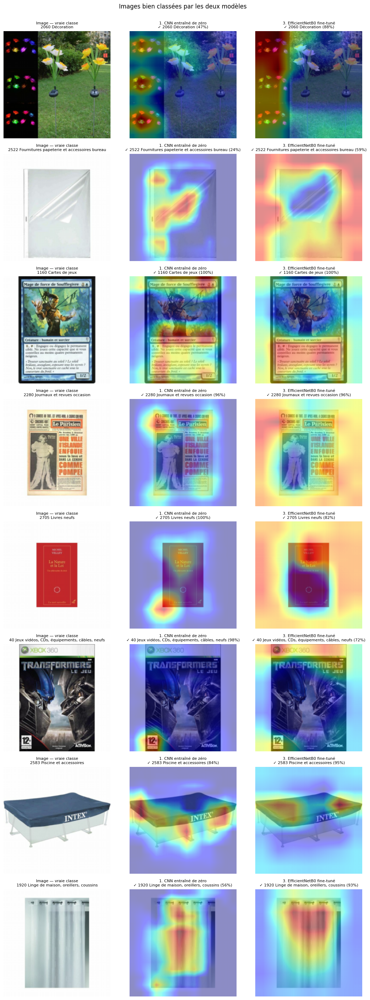

In [7]:
both_right = val[(val["pred_cnn_scratch"] == y_true) & (val["pred_efficientnet_finetuned"] == y_true)]
sample_both = (
    both_right.sample(frac=1, random_state=SEED)
    .groupby("class_index").head(1)
    .head(8)
)
compare_models(sample_both, "Images bien classées par les deux modèles")


## 4. Ce que le transfert corrige

Images mal classées par le CNN de zéro mais bien classées par le modèle fine-tuné. La comparaison
des cartes montre l'indice que la baseline a manqué.


2,501 images corrigées par le transfert (15.2% de la validation)
1,330 images dégradées par le transfert (8.1% de la validation)


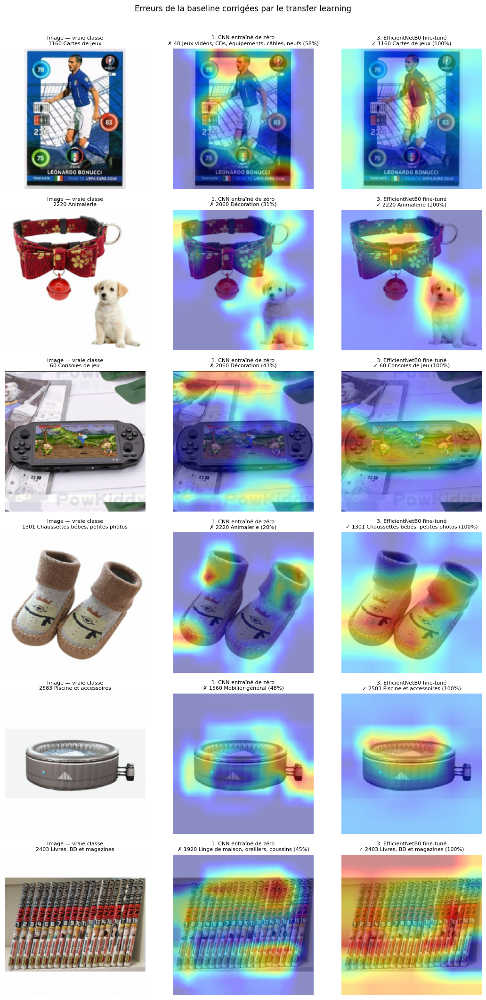

In [8]:
fixed = val[(val["pred_cnn_scratch"] != y_true) & (val["pred_efficientnet_finetuned"] == y_true)]
print(f"{len(fixed):,} images corrigées par le transfert ({len(fixed) / len(val):.1%} de la validation)")
broken = val[(val["pred_cnn_scratch"] == y_true) & (val["pred_efficientnet_finetuned"] != y_true)]
print(f"{len(broken):,} images dégradées par le transfert ({len(broken) / len(val):.1%} de la validation)")
sample_fixed = fixed.sort_values("conf_efficientnet_finetuned", ascending=False).groupby(
    "class_index", group_keys=False).head(1).head(6)
compare_models(sample_fixed, "Erreurs de la baseline corrigées par le transfer learning")


## 5. Erreurs confiantes du modèle fine-tuné

Pour chaque erreur, deux cartes : les zones qui soutiennent la classe **prédite** et celles qui
soutiennent la classe **réelle**. Si les deux pointent vers le même objet, l'image est ambiguë entre
les deux catégories ; si la classe prédite s'appuie sur un détail secondaire, le modèle a suivi un
indice trompeur.


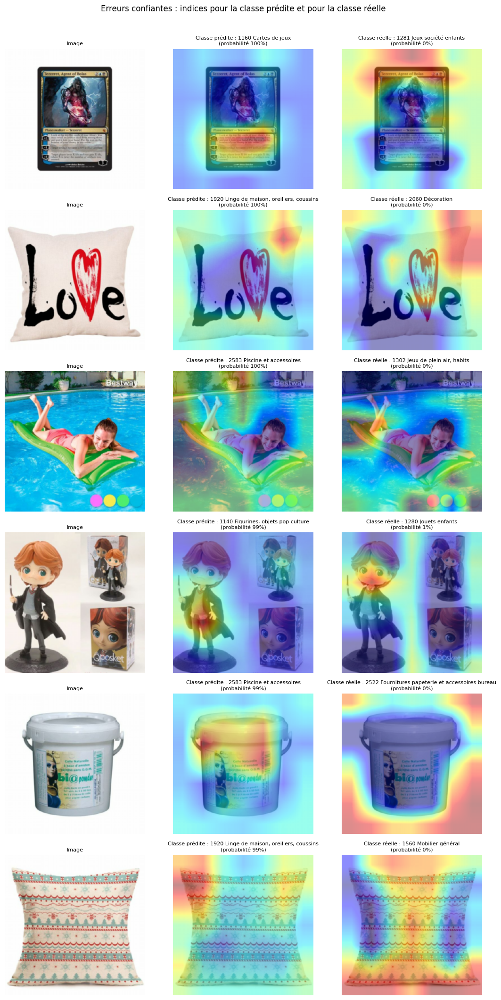

In [9]:
name = "efficientnet_finetuned"
wrong = val[val[f"pred_{name}"] != y_true].sort_values(f"conf_{name}", ascending=False)
wrong = wrong.groupby("class_index", group_keys=False).head(1).head(6)
images = load_images(wrong["image_path"])
cams_pred, probs, _ = gradcam(name, images)
cams_true, _, _ = gradcam(name, images, wrong["class_index"].to_numpy())

fig, axes = plt.subplots(len(wrong), 3, figsize=(11, 3.6 * len(wrong)))
axes = np.atleast_2d(axes)
for i, row in enumerate(wrong.itertuples()):
    pred = getattr(row, f"pred_{name}")
    axes[i, 0].imshow(images[i].astype("uint8"))
    axes[i, 0].set_title("Image", fontsize=8)
    axes[i, 0].axis("off")
    show_cam(axes[i, 1], images[i], cams_pred[i],
             f"Classe prédite : {short_label(pred)}\n(probabilité {probs[i, pred]:.0%})")
    show_cam(axes[i, 2], images[i], cams_true[i],
             f"Classe réelle : {short_label(row.class_index)}\n(probabilité {probs[i, row.class_index]:.0%})")
fig.suptitle("Erreurs confiantes : indices pour la classe prédite et pour la classe réelle", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
plt.show()


## 6. Une carte par catégorie

Pour chaque catégorie, l'image la mieux reconnue par le modèle fine-tuné. Ces cartes résument les
indices visuels typiques de chaque classe : couverture d'un livre, forme d'un meuble, emballage, etc.


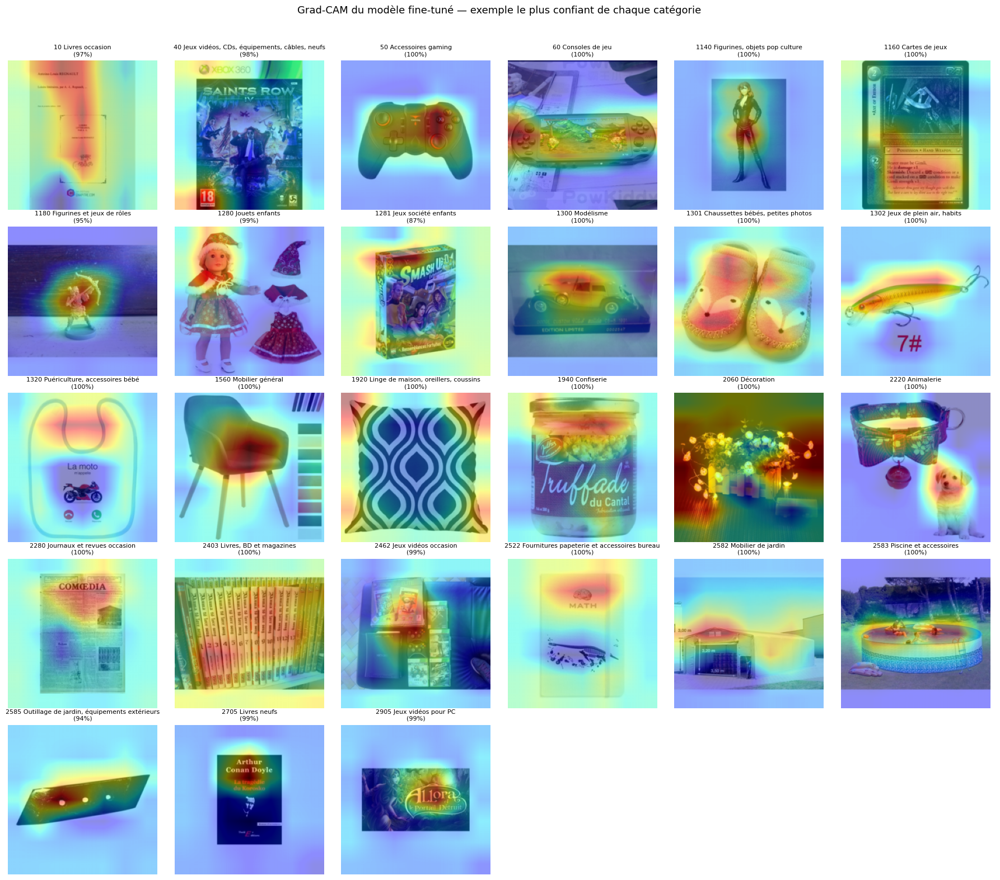

In [10]:
best_per_class = (
    val[val["pred_efficientnet_finetuned"] == y_true]
    .sort_values("conf_efficientnet_finetuned", ascending=False)
    .groupby("class_index").head(1)
    .sort_values("class_index")
)
images = load_images(best_per_class["image_path"])
cams, _, _ = gradcam("efficientnet_finetuned", images)
fig, axes = plt.subplots(5, 6, figsize=(18, 16))
for ax in axes.flat:
    ax.axis("off")
for ax, image, cam, row in zip(axes.flat, images, cams, best_per_class.itertuples()):
    show_cam(ax, image, cam, f"{short_label(row.class_index)}\n({row.conf_efficientnet_finetuned:.0%})")
fig.suptitle("Grad-CAM du modèle fine-tuné — exemple le plus confiant de chaque catégorie", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
plt.show()


## 7. Test de fidélité : les zones Grad-CAM comptent-elles vraiment ?

Une carte peut être jolie sans refléter le raisonnement du modèle. Pour le vérifier, on masque 20 % des
pixels de chaque image (remplacés par la couleur moyenne de l'image) selon trois stratégies, puis on
mesure la chute de probabilité de la classe initialement prédite :

- **zones les plus importantes** selon Grad-CAM ;
- **zones Grad-CAM d'une autre image** : même forme de masque, mais placée sans lien avec l'image, ce
  qui sert de témoin ;
- **zones les moins importantes** selon Grad-CAM.

Si Grad-CAM est fidèle, la première stratégie doit faire chuter la confiance bien plus que les deux
autres. L'échantillon compte jusqu'à 20 images par catégorie.


In [11]:
MASK_FRACTION = 0.20
rng = np.random.default_rng(SEED)
fidelity_sample = val.sample(frac=1, random_state=SEED).groupby("class_index").head(20)

def mask_by_cam(images, cams, mode):
    flat = cams.reshape(len(cams), -1) + rng.uniform(0, 1e-6, size=(len(cams), cams[0].size))
    k = int(MASK_FRACTION * flat.shape[1])
    order = np.argsort(-flat if mode == "top" else flat, axis=1)[:, :k]
    mask = np.zeros_like(flat, dtype=bool)
    np.put_along_axis(mask, order, True, axis=1)
    mask = mask.reshape(cams.shape)[..., None]
    fill = images.mean(axis=(1, 2), keepdims=True)
    return np.where(mask, fill, images)

fidelity_rows = []
for name in GRADCAM_MODELS:
    for start in range(0, len(fidelity_sample), BATCH_SIZE):
        batch = fidelity_sample.iloc[start:start + BATCH_SIZE]
        images = load_images(batch["image_path"])
        cams, probs, classes = gradcam(name, images)
        base = probs[np.arange(len(batch)), classes]
        variants = {
            "zones les plus importantes": mask_by_cam(images, cams, "top"),
            "zones d'une autre image (témoin)": mask_by_cam(images, np.roll(cams, 1, axis=0), "top"),
            "zones les moins importantes": mask_by_cam(images, cams, "bottom"),
        }
        for strategy, masked in variants.items():
            masked_probs = models[name].predict_on_batch(masked)
            masked_probs = np.asarray(masked_probs)
            fidelity_rows.append(pd.DataFrame({
                "modèle": labels[name],
                "masque": strategy,
                "chute de confiance": base - masked_probs[np.arange(len(batch)), classes],
                "prédiction changée": masked_probs.argmax(axis=1) != classes,
            }))

fidelity = pd.concat(fidelity_rows, ignore_index=True)
fidelity_summary = fidelity.groupby(["modèle", "masque"], sort=False).mean()
fidelity_summary.to_csv(ARTIFACTS_DIR / "gradcam_fidelity.csv")
display(fidelity_summary.style.format({"chute de confiance": "{:+.3f}", "prédiction changée": "{:.1%}"}))
print(f"Images testées par modèle : {len(fidelity_sample)}")


2026-10-14 19:29:58.674995: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Images testées par modèle : 540


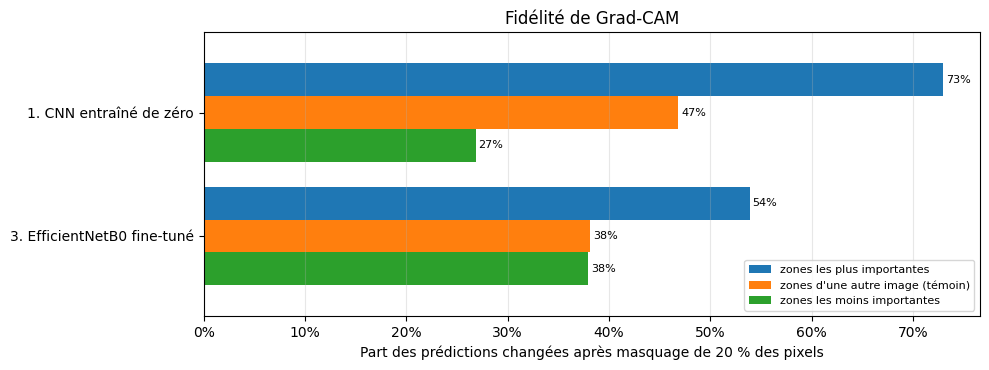

In [12]:
from matplotlib.ticker import PercentFormatter

ax = fidelity_summary["prédiction changée"].unstack("masque").plot.barh(figsize=(10, 3.8), width=0.8)
ax.invert_yaxis()
ax.set_xlabel("Part des prédictions changées après masquage de 20 % des pixels")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="x", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt=lambda value: f"{value:.0%}", fontsize=8, padding=2)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Fidélité de Grad-CAM")
plt.tight_layout()
plt.show()
